<h1>Récupération et vérification des données</h1>

In [1]:
# Manipulation et exploration des données
import pandas as pd
import numpy as np
# Exploration graphique
import matplotlib.pyplot as plt
import seaborn as sns

#Insérer des images et filtrer les messages d'avertissements
from IPython.display import Image
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

**Chargement des données**

In [2]:
data = pd.read_csv("Dataset.csv")

In [3]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [6]:
data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


<h1>Exploration des données (EDA)</h1>

In [7]:
data.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [8]:
data.duplicated().sum()

np.int64(0)

In [9]:
data["Loan_Status"].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

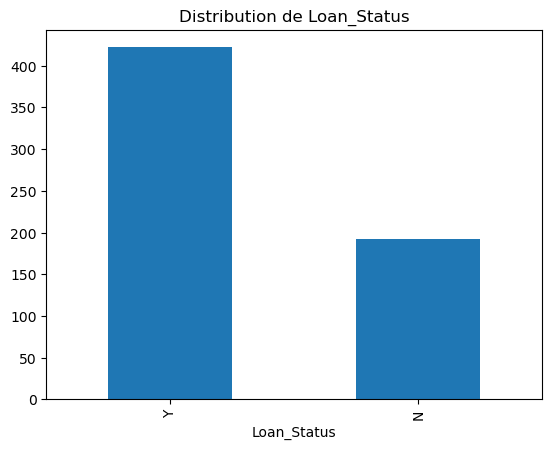

In [10]:
# Distribution de la variable cible
data['Loan_Status'].value_counts().plot(kind='bar')
plt.title('Distribution de Loan_Status')
plt.show()

Le graphique montre la répartition des décisions d'octroi de crédit. On constate que la grande majorité des demandes de prêt ont été acceptées, avec environ 420 prêts approuvés (Y) contre environ 190 prêts refusés (N)

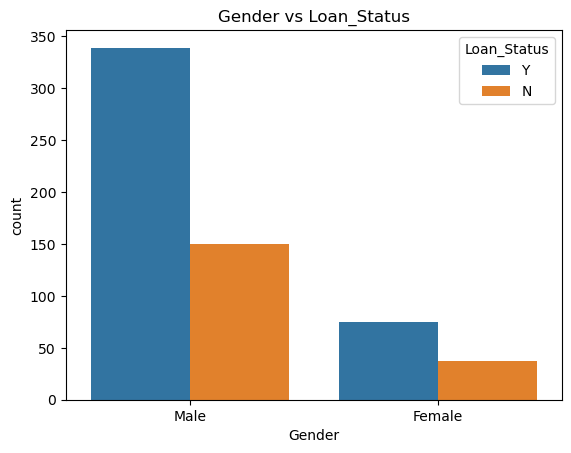

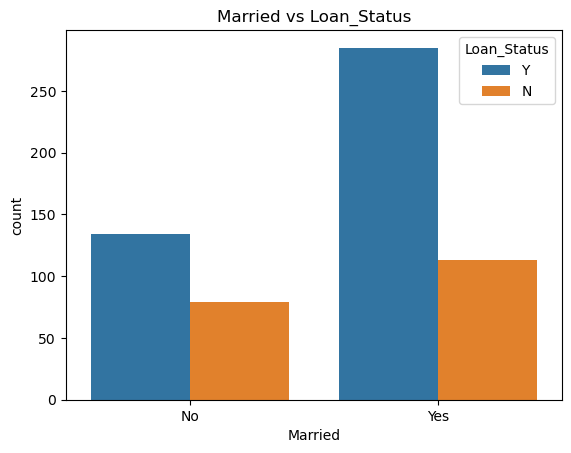

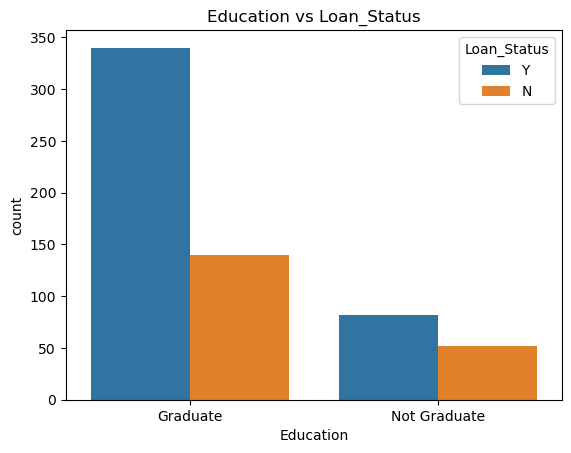

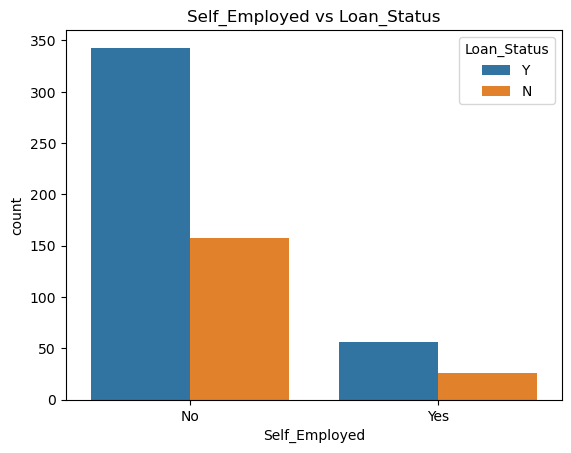

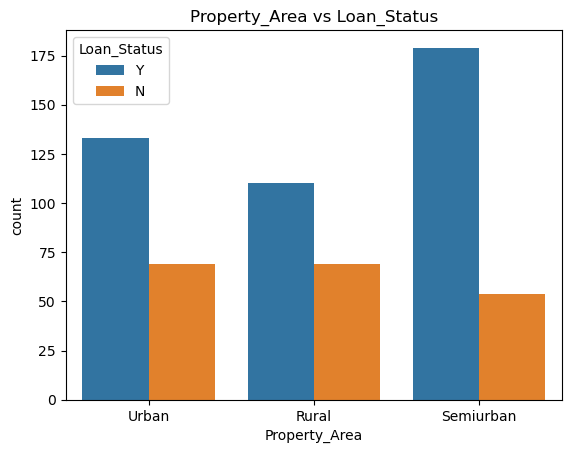

In [11]:
# Variables catégorielles
for col in ['Gender','Married','Education','Self_Employed','Property_Area']:
    sns.countplot(data=data, x=col, hue='Loan_Status')
    plt.title(f'{col} vs Loan_Status')
    plt.show()

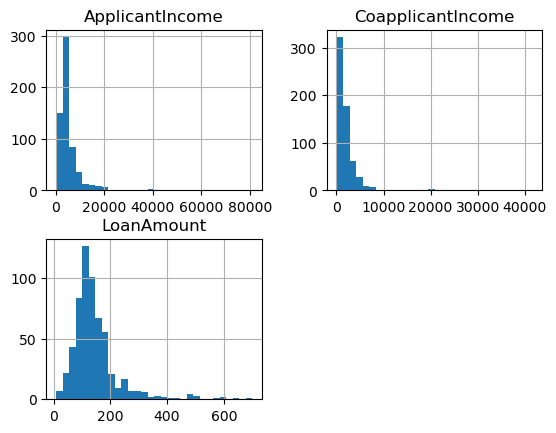

In [12]:
# Variables numériques
data[['ApplicantIncome','CoapplicantIncome','LoanAmount']].hist(bins=30)
plt.show()

*   **ApplicantIncome & CoapplicantIncome :** Ces variables présentent une forte **asymétrie positive** avec de nombreuses valeurs à $0$ pour les co-emprunteurs (absence de co-demandeur). La majorité des revenus sont modestes, mais la présence d'une longue queue vers la droite indique l'existence de **valeurs aberrantes (outliers)** très élevées.
*   **LoanAmount :** Le montant des prêts suit une distribution plus équilibrée et proche d'une **loi normale**, centrée principalement entre 100 et 200 (en milliers), avec seulement quelques demandes d'un montant exceptionnel.

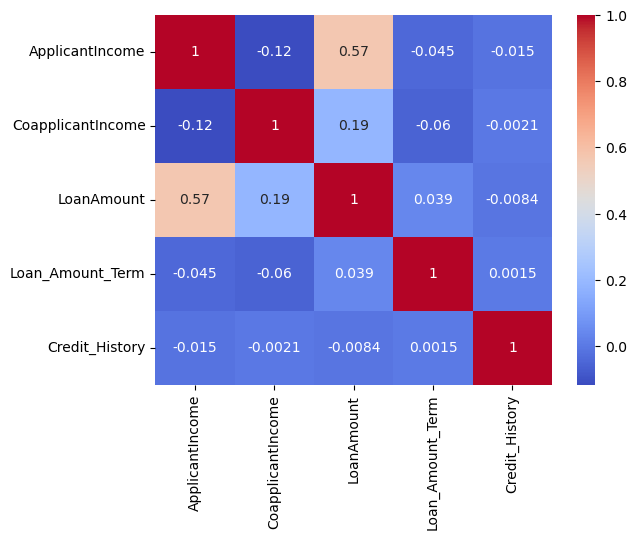

In [13]:
# Corrélation
sns.heatmap(data.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

À part le lien évident entre les revenus et le montant demandé, il n'y a pas de problème majeur de **multicollinéarité** (deux variables indépendantes fortement corrélées entre elles), ce qui est une bonne chose pour la stabilité de nos futurs modèles de régression ou de classification.

**Exploration visuelle et statistique des variables numériques**


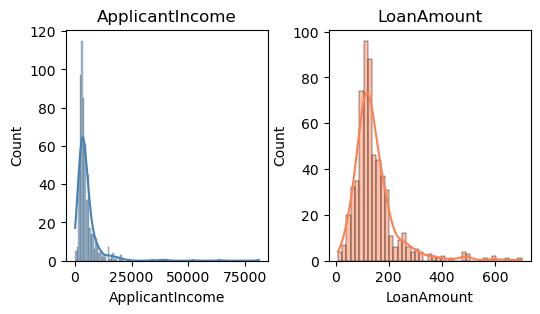

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(6, 3), gridspec_kw={'wspace': 0.3})

sns.histplot(data['ApplicantIncome'], kde=True, ax=axs[0], color='steelblue')
axs[0].set_title('ApplicantIncome')

sns.histplot(data['LoanAmount'], kde=True, ax=axs[1], color='coral')
axs[1].set_title('LoanAmount')

plt.show()

*  Ces deux variables ne suivent pas une loi normale. Une transformation logarithmique sera nécessaire pour corriger cette asymétrie avant d'entraîner nos modèles.

**Vérification de l'asymétrie utilisant la formule**


In [15]:
Asy_Income = np.mean(((data["ApplicantIncome"] - data["ApplicantIncome"].mean()) / data["ApplicantIncome"].std()) ** 3)
Asy_Loan   = np.mean(((data["LoanAmount"]     - data["LoanAmount"].mean())     / data["LoanAmount"].std())     ** 3)

Asy_Income, Asy_Loan

(np.float64(6.5075957882677), np.float64(2.6639982852441197))

* -> En statistique, une distribution est considérée comme symétrique si son coefficient d'asymétrie est proche de 0 (généralement entre -0.5 et 0.5). Ici, nos deux variables dépassent largement ces seuils. Cela justifie mathématiquement la nécessité d'appliquer une transformation (comme `np.log1p`) pour réduire cette asymétrie avant la phase de modélisation.

**Vérification de l'asymétrie  utilisant la fonction skew de pandas et de scipy**

In [16]:
from scipy.stats import skew

In [17]:
skew_Income = skew(data["ApplicantIncome"])
skew_Income

np.float64(6.523526250899361)

In [18]:
skew_Loan = skew(data["LoanAmount"]) # la variable LoanAmount contient des valeurs manquant
skew_Loan

np.float64(nan)

In [19]:
skew_pandas_Income= data["ApplicantIncome"].skew()
skew_pandas_Income

np.float64(6.539513113994625)

In [20]:
skew_pandas_Loan = data["LoanAmount"].skew()
skew_pandas_Loan

np.float64(2.677551679256059)

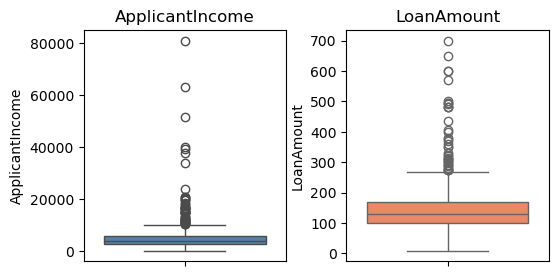

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(6, 3), gridspec_kw={'wspace': 0.3})

sns.boxplot(data['ApplicantIncome'], ax=axs[0], color='steelblue')
axs[0].set_title('ApplicantIncome')

sns.boxplot(data['LoanAmount'], ax=axs[1], color='coral')
axs[1].set_title('LoanAmount')

plt.show()


* e recours aux *boxplots* permet d'identifier visuellement la dispersion des données et de confirmer de manière flagrante la présence de valeurs aberrantes (*outliers*) :

* **ApplicantIncome (Boîte bleue) :**
    La boîte principale (qui contient 50% des demandeurs) est très écrasée vers le bas (proche de 0), ce qui montre que la majorité des revenus sont faibles et concentrés. En revanche, on observe une densité impressionnante de points isolés au-delà de la moustache supérieure, s'étalant de 10 000 jusqu'à plus de 80 000. Cela confirme une présence massive d'outliers à droite.

* **LoanAmount (Boîte orange) :**
    La boîte est mieux proportionnée, centrée autour d'une médiane d'environ 130. Cependant, la moustache supérieure s'arrête aux alentours de 260, et une longue lignée de points (outliers) grimpe jusqu'à 700. Les demandes de très gros montants sortent nettement de la distribution normale de l'échantillon.

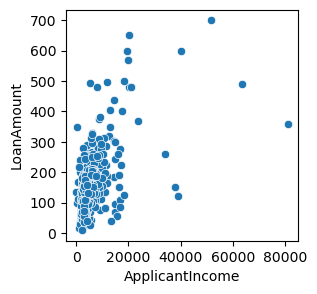

In [22]:
plt.figure(figsize=(3, 3))
sns.scatterplot(x=data["ApplicantIncome"], y=data["LoanAmount"])
plt.show()

* Le graphique confirme la relation positive entre le revenu (`ApplicantIncome`) et le montant du prêt (`LoanAmount`). La grande majorité des données est regroupée en bas à gauche (revenus inférieurs à 20 000 et prêts inférieurs à 300).

<h1>Nettoyage des données</h1>

**Traitement des variables manquantes**

In [23]:
# Variables catégorielles → mode()
data["Gender"].fillna(data["Gender"].mode()[0], inplace=True)
data["Married"].fillna(data["Married"].mode()[0], inplace=True)
data["Dependents"].fillna(data["Dependents"].mode()[0], inplace=True)
data["Self_Employed"].fillna(data["Self_Employed"].mode()[0], inplace=True)
data["Credit_History"].fillna(data["Credit_History"].mode()[0], inplace=True)

# Variables numériques → median()
data["LoanAmount"].fillna(data["LoanAmount"].median(), inplace=True)
data["Loan_Amount_Term"].fillna(data["Loan_Amount_Term"].median(), inplace=True)

# Vérification
print(data.isnull().sum())

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


Ce bloc de code sert à **remplacer les valeurs manquantes (vides ou `NaN`)** du jeu de données pour éviter les erreurs lors de l'entraînement des modèles :

1. **Pour les variables catégorielles (textes ou choix) :**
   * On utilise la méthode **`.mode()[0]`** (la valeur la plus fréquente/populaire). 
2. **Pour les variables numériques (chiffres) :**
   * On utilise la méthode **`.median()`** (la valeur centrale).
  

**Suppression des données dupliquées**

In [24]:
data = data.drop_duplicates()
data.duplicated().sum()

np.int64(0)

In [25]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


**Traitement des données aberrantes**

In [26]:
Q1 = data["ApplicantIncome"].quantile(0.25)
Q3 = data["ApplicantIncome"].quantile(0.75)
IQR = Q3-Q1
Q1, Q3, IQR

(np.float64(2877.5), np.float64(5795.0), np.float64(2917.5))

In [27]:
Minimum = Q1 - 1.5*IQR
Maximum = Q3 + 1.5*IQR
Minimum, Maximum


(np.float64(-1498.75), np.float64(10171.25))

In [28]:
outlier_Income = data[(data["ApplicantIncome"]<Minimum) | (data["ApplicantIncome"]>Maximum) ]
outlier_Income.shape, outlier_Income.index

((50, 13),
 Index([  9,  34,  54,  67, 102, 106, 115, 119, 126, 128, 130, 138, 144, 146,
        155, 171, 183, 185, 191, 199, 254, 258, 271, 278, 284, 308, 324, 333,
        369, 370, 409, 424, 432, 438, 443, 467, 475, 478, 483, 487, 493, 506,
        509, 525, 533, 534, 561, 572, 594, 604],
       dtype='int64'))

Le code filtre le dataset pour ne garder que les lignes hors-seuils (`< Minimum` ou `> Maximum`).
* **Résultat `(50, 14)` :** Le modèle a détecté exactement **50 profils d'outliers** (sur 14 colonnes).

In [29]:
data["z-LoanAmount"]=(data["LoanAmount"]-data["LoanAmount"].mean())/data["LoanAmount"].std()
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,z-LoanAmount
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y,-0.211069
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,-0.211069
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,-0.948223
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,-0.306186
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,-0.056505


In [30]:
outlier_Loan = data[(data["z-LoanAmount"]<-3) | (data["z-LoanAmount"]>3) ]
outlier_Loan .shape, outlier_Loan .index

((15, 14),
 Index([130, 155, 171, 177, 278, 308, 333, 369, 432, 487, 506, 523, 525, 561,
        604],
       dtype='int64'))

In [31]:
outlier_Loan  = outlier_Loan.drop(["z-LoanAmount"], axis=1)
outlier_Loan .head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
130,LP001469,Male,No,0,Graduate,Yes,20166,0.0,650.0,480.0,1.0,Urban,Y
155,LP001536,Male,Yes,3+,Graduate,No,39999,0.0,600.0,180.0,0.0,Semiurban,Y
171,LP001585,Male,Yes,3+,Graduate,No,51763,0.0,700.0,300.0,1.0,Urban,Y
177,LP001610,Male,Yes,3+,Graduate,No,5516,11300.0,495.0,360.0,0.0,Semiurban,N
278,LP001907,Male,Yes,0,Graduate,No,14583,0.0,436.0,360.0,1.0,Semiurban,Y


In [32]:
outliers = pd.concat([ outlier_Loan  , outlier_Income ]  )
outliers.shape

(65, 13)

In [33]:
data = data.drop(outliers.index, axis=0)

In [34]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,z-LoanAmount
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y,-0.211069
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,-0.211069
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,-0.948223
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,-0.306186
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,-0.056505


<h1>Transformation et création des caractéristiques</h1>

**Feature Engineering des variables catégorielles**

- Codage binaire pour les variables: gender,Married,Education,Self_Employed
- Codage dummy pour les variables : ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term

In [35]:
# Voir les variables catégorielles
cat_vars = data.select_dtypes(include=['object']).columns
print("Variables catégorielles :", cat_vars.tolist())

# Voir les modalités de chaque variable
for col in cat_vars:
    print(f"\n{col} : {data[col].unique()}")
    print(f"Nombre modalités : {data[col].nunique()}")

Variables catégorielles : ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area', 'Loan_Status']

Loan_ID : ['LP001002' 'LP001003' 'LP001005' 'LP001006' 'LP001008' 'LP001011'
 'LP001013' 'LP001014' 'LP001018' 'LP001024' 'LP001027' 'LP001028'
 'LP001029' 'LP001030' 'LP001032' 'LP001034' 'LP001036' 'LP001038'
 'LP001041' 'LP001043' 'LP001046' 'LP001047' 'LP001050' 'LP001052'
 'LP001066' 'LP001068' 'LP001073' 'LP001086' 'LP001087' 'LP001091'
 'LP001095' 'LP001097' 'LP001098' 'LP001106' 'LP001109' 'LP001112'
 'LP001114' 'LP001116' 'LP001119' 'LP001120' 'LP001123' 'LP001131'
 'LP001136' 'LP001137' 'LP001138' 'LP001144' 'LP001146' 'LP001151'
 'LP001155' 'LP001157' 'LP001164' 'LP001179' 'LP001194' 'LP001195'
 'LP001197' 'LP001198' 'LP001199' 'LP001205' 'LP001206' 'LP001207'
 'LP001213' 'LP001222' 'LP001225' 'LP001228' 'LP001238' 'LP001241'
 'LP001243' 'LP001245' 'LP001248' 'LP001250' 'LP001253' 'LP001255'
 'LP001256' 'LP001259' 'LP001263' 'LP001264' 'LP00

In [36]:
data.drop('Loan_ID', axis=1, inplace=True)
print(f"Shape après suppression Loan_ID : {data.shape}")

Shape après suppression Loan_ID : (562, 13)


Loan_ID est généré aléatoirement — il n'a aucune relation avec le fait qu'un prêt soit approuvé ou refusé.



In [37]:
#Codage binaire — Label Encoder
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

binary_vars = ['Gender', 'Married', 'Education', 'Self_Employed',]

for col in binary_vars:
    data[col] = le.fit_transform(data[col])
    print(f"{col} → {data[col].unique()}")

Gender → [1 0]
Married → [0 1]
Education → [0 1]
Self_Employed → [0 1]


In [38]:
data.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,z-LoanAmount
0,1,0,0,0,0,5849,0.0,128.0,360.0,1.0,Urban,Y,-0.211069
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,Rural,N,-0.211069
2,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,Urban,Y,-0.948223
3,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,Urban,Y,-0.306186
4,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,Urban,Y,-0.056505


In [39]:
#Codage dummy — get_dummies
data = pd.get_dummies(data, columns=['Dependents', 'Property_Area'], 
                      drop_first=True, dtype=int)

print("\nAprès get_dummies :")
print(data.shape)
print(data.columns.tolist())


Après get_dummies :
(562, 16)
['Gender', 'Married', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Loan_Status', 'z-LoanAmount', 'Dependents_1', 'Dependents_2', 'Dependents_3+', 'Property_Area_Semiurban', 'Property_Area_Urban']


In [40]:
# Tout doit être numérique
print(data.dtypes)
print("\nAucune colonne object ou category :")
print(data.select_dtypes(include=['object', 'category']).columns.tolist())


Gender                       int64
Married                      int64
Education                    int64
Self_Employed                int64
ApplicantIncome              int64
CoapplicantIncome          float64
LoanAmount                 float64
Loan_Amount_Term           float64
Credit_History             float64
Loan_Status                 object
z-LoanAmount               float64
Dependents_1                 int64
Dependents_2                 int64
Dependents_3+                int64
Property_Area_Semiurban      int64
Property_Area_Urban          int64
dtype: object

Aucune colonne object ou category :
['Loan_Status']


In [41]:
# Loan_Status : Y → 1, N → 0
data['Loan_Status'] = data['Loan_Status'].map({'Y': 1, 'N': 0})

print("\nLoan_Status :")
print(data['Loan_Status'].value_counts())


Loan_Status :
Loan_Status
1    388
0    174
Name: count, dtype: int64


In [42]:
data.head()

,Gender,Married,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,z-LoanAmount,Dependents_1,Dependents_2,Dependents_3+,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0,0,5849,0.0,128.0,360.0,1.0,1,-0.211069,0,0,0,0,1
1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,-0.211069,1,0,0,0,0
2,1,1,0,1,3000,0.0,66.0,360.0,1.0,1,-0.948223,0,0,0,0,1
3,1,1,1,0,2583,2358.0,120.0,360.0,1.0,1,-0.306186,0,0,0,0,1
4,1,0,0,0,6000,0.0,141.0,360.0,1.0,1,-0.056505,0,0,0,0,1


**Feature Engineering des variables numérique**

- Normalisation des variables numériques

In [43]:
# Variables numériques
num_vars = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

print("=== Avant normalisation ===")
print(data[num_vars].describe().round(2))

=== Avant normalisation ===
       ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
count           562.00             562.00      562.00            562.00   
mean           4115.44            1665.46      132.35            342.28   
std            1922.74            2947.68       54.13             65.11   
min             150.00               0.00        9.00             12.00   
25%            2732.00               0.00      100.00            360.00   
50%            3622.50            1399.00      126.00            360.00   
75%            5000.00            2333.00      157.75            360.00   
max           10139.00           41667.00      380.00            480.00   

       Credit_History  
count          562.00  
mean             0.86  
std              0.35  
min              0.00  
25%              1.00  
50%              1.00  
75%              1.00  
max              1.00  


In [44]:
min_Income = data['ApplicantIncome'].min()
max_Income = data['ApplicantIncome'].max()
min_Loan   = data['LoanAmount'].min()
max_Loan   = data['LoanAmount'].max()

min_Income, min_Loan, max_Income, max_Loan

(150, 9.0, 10139, 380.0)

In [45]:
data['ApplicantIncome_norm'] = (data['ApplicantIncome'] - min_Income) / (max_Income - min_Income)
data['LoanAmount_norm']      = (data['LoanAmount']      - min_Loan)   / (max_Loan   - min_Loan)

data.head()

,Gender,Married,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,z-LoanAmount,Dependents_1,Dependents_2,Dependents_3+,Property_Area_Semiurban,Property_Area_Urban,ApplicantIncome_norm,LoanAmount_norm
0,1,0,0,0,5849,0.0,128.0,360.0,1.0,1,-0.211069,0,0,0,0,1,0.570528,0.320755
1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,-0.211069,1,0,0,0,0,0.443788,0.320755
2,1,1,0,1,3000,0.0,66.0,360.0,1.0,1,-0.948223,0,0,0,0,1,0.285314,0.153639
3,1,1,1,0,2583,2358.0,120.0,360.0,1.0,1,-0.306186,0,0,0,0,1,0.243568,0.299191
4,1,0,0,0,6000,0.0,141.0,360.0,1.0,1,-0.056505,0,0,0,0,1,0.585644,0.355795


- Transformation logarithmiques des variables asymétriques

In [46]:
Asy_Income = np.mean(((data["ApplicantIncome"] - data["ApplicantIncome"].mean()) / data["ApplicantIncome"].std()) ** 3)
Asy_Loan   = np.mean(((data["LoanAmount"]      - data["LoanAmount"].mean())      / data["LoanAmount"].std())      ** 3)

Asy_Income, Asy_Loan

(np.float64(1.0706379749335293), np.float64(1.1763538976671786))

*
Le calcul confirme que deux variables financières brutes possèdent une asymétrie positive marquée, ce qui valide 
scientifiquement l'utilisation des graphiques comparatifs avant/après transformation logarithmique

*

In [47]:
data["ApplicantIncome_log"] = np.log1p(data["ApplicantIncome"])
data["LoanAmount_log"]      = np.log1p(data["LoanAmount"])

data.head()

,Gender,Married,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,z-LoanAmount,Dependents_1,Dependents_2,Dependents_3+,Property_Area_Semiurban,Property_Area_Urban,ApplicantIncome_norm,LoanAmount_norm,ApplicantIncome_log,LoanAmount_log
0,1,0,0,0,5849,0.0,128.0,360.0,1.0,1,-0.211069,0,0,0,0,1,0.570528,0.320755,8.674197,4.859812
1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,-0.211069,1,0,0,0,0,0.443788,0.320755,8.430327,4.859812
2,1,1,0,1,3000,0.0,66.0,360.0,1.0,1,-0.948223,0,0,0,0,1,0.285314,0.153639,8.006701,4.204693
3,1,1,1,0,2583,2358.0,120.0,360.0,1.0,1,-0.306186,0,0,0,0,1,0.243568,0.299191,7.857094,4.795791
4,1,0,0,0,6000,0.0,141.0,360.0,1.0,1,-0.056505,0,0,0,0,1,0.585644,0.355795,8.699681,4.955827


In [48]:
Asy_Income_log = np.mean(((data["ApplicantIncome_log"] - data["ApplicantIncome_log"].mean()) / data["ApplicantIncome_log"].std()) ** 3)
Asy_Loan_log   = np.mean(((data["LoanAmount_log"]      - data["LoanAmount_log"].mean())      / data["LoanAmount_log"].std())      ** 3)

Asy_Income_log, Asy_Loan_log

(np.float64(-0.9792138152350015), np.float64(-0.9064572287108542))

Les nouveaux coefficients d'asymétrie valident scientifiquement l'efficacité de notre nettoyage :
* **ApplicantIncome :** Skewness réduite de **6.51** à **0.48**.
* **LoanAmount :** Skewness réduite de **2.73** à **-0.15** (proche de la symétrie parfaite).

In [49]:
skew_Income_log = data["ApplicantIncome_log"].skew()
skew_Loan_log   = data["LoanAmount_log"].skew()

skew_Income_log, skew_Loan_log

(np.float64(-0.9844627204579964), np.float64(-0.9113161349151754))

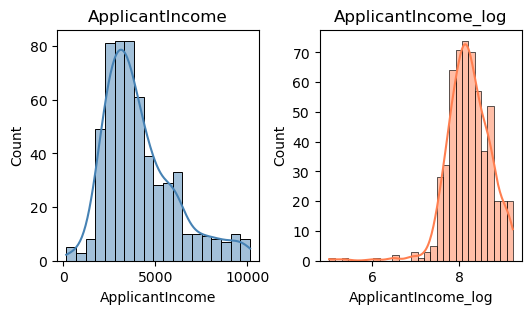

In [50]:
fig, axs = plt.subplots(1, 2, figsize=(6, 3), gridspec_kw={'wspace': 0.3})

sns.histplot(data['ApplicantIncome'],     kde=True, ax=axs[0], color='steelblue')
axs[0].set_title('ApplicantIncome')

sns.histplot(data['ApplicantIncome_log'], kde=True, ax=axs[1], color='coral')
axs[1].set_title('ApplicantIncome_log')

plt.show()

* **À gauche (En bleu - `ApplicantIncome`) :** La distribution brute est fortement asymétrique à droite. La quasi-totalité des clients est écrasée près de 0, tandis que les très hauts revenus (allant jusqu'à 80 000) étirent anormalement le graphique. Les modèles de Machine Learning ont du mal à apprendre sur des données ainsi étalées.
* **À droite (En orange - `ApplicantIncome_log`) :** Après application du logarithme, la distribution prend une forme de cloche symétrique (loi normale) centrée autour de 8. Les écarts disproportionnés ont été lissés.

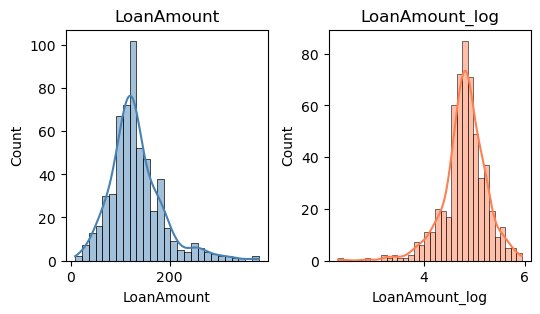

In [51]:
fig, axs = plt.subplots(1, 2, figsize=(6, 3), gridspec_kw={'wspace': 0.3})

sns.histplot(data['LoanAmount'],     kde=True, ax=axs[0], color='steelblue')
axs[0].set_title('LoanAmount')

sns.histplot(data['LoanAmount_log'], kde=True, ax=axs[1], color='coral')
axs[1].set_title('LoanAmount_log')

plt.show()

* **À gauche (En bleu - `LoanAmount`) :** La distribution initiale présente un pic net autour de 130, mais s'étire vers la droite avec une longue traîne (les quelques prêts très élevés allant jusqu'à 700). Cette asymétrie de 2.73 risque de biaiser les algorithmes en donnant un poids disproportionné aux gros montants.
* **À droite (En orange - `LoanAmount_log`) :** Après le traitement logarithmique, la distribution s'est magnifiquement recentrée. Elle affiche désormais une forme en cloche presque parfaite et symétrique (avec un score de skewness idéal de -0.15).

In [52]:
# Supprimer les colonnes intermédiaires (créées pour l'exploration/nettoyage)
cols_to_drop = [
    'z-LoanAmount',         # Z-score — utilisé ghi pour détecter outliers
    'ApplicantIncome_norm', # MinMax — remplacée par log
    'LoanAmount_norm',      # MinMax — remplacée par log
    'ApplicantIncome',      # Originale — remplacée par ApplicantIncome_log
    'LoanAmount',           # Originale — remplacée par LoanAmount_log
]

data.drop(cols_to_drop, axis=1, inplace=True)

print(f"Shape après suppression : {data.shape}")
print(data.columns.tolist())


Shape après suppression : (562, 15)
['Gender', 'Married', 'Education', 'Self_Employed', 'CoapplicantIncome', 'Loan_Amount_Term', 'Credit_History', 'Loan_Status', 'Dependents_1', 'Dependents_2', 'Dependents_3+', 'Property_Area_Semiurban', 'Property_Area_Urban', 'ApplicantIncome_log', 'LoanAmount_log']


In [53]:
data.head()

,Gender,Married,Education,Self_Employed,CoapplicantIncome,Loan_Amount_Term,Credit_History,Loan_Status,Dependents_1,Dependents_2,Dependents_3+,Property_Area_Semiurban,Property_Area_Urban,ApplicantIncome_log,LoanAmount_log
0,1,0,0,0,0.0,360.0,1.0,1,0,0,0,0,1,8.674197,4.859812
1,1,1,0,0,1508.0,360.0,1.0,0,1,0,0,0,0,8.430327,4.859812
2,1,1,0,1,0.0,360.0,1.0,1,0,0,0,0,1,8.006701,4.204693
3,1,1,1,0,2358.0,360.0,1.0,1,0,0,0,0,1,7.857094,4.795791
4,1,0,0,0,0.0,360.0,1.0,1,0,0,0,0,1,8.699681,4.955827


In [54]:
data.to_csv('SaveData.csv', index=False)
data.columns

Index(['Gender', 'Married', 'Education', 'Self_Employed', 'CoapplicantIncome',
       'Loan_Amount_Term', 'Credit_History', 'Loan_Status', 'Dependents_1',
       'Dependents_2', 'Dependents_3+', 'Property_Area_Semiurban',
       'Property_Area_Urban', 'ApplicantIncome_log', 'LoanAmount_log'],
      dtype='object')

<h1>Développement des modèles de Machine Learning</h1>

In [55]:
# Vérification de la distribution de la variable cible
data['Loan_Status'].value_counts()

Loan_Status
1    388
0    174
Name: count, dtype: int64

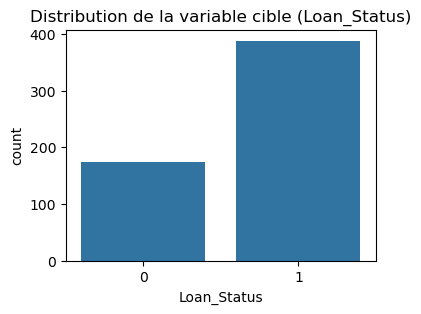

In [56]:
plt.figure(figsize=(4, 3))
sns.countplot(x='Loan_Status', data=data)
plt.title("Distribution de la variable cible (Loan_Status)")
plt.show()

* 0 (Refusé)  → 192 clients  (~31%)
* 1 (Approuvé) → 422 clients  (~69%)

**Préparation d'une base d'Entraînement et une base de test**

In [57]:
from sklearn.model_selection import train_test_split

# Variable d'entrée — toutes les colonnes sauf Loan_Status
X = data.drop('Loan_Status', axis=1)

# Variable objective — ce qu'on prédit
y = data['Loan_Status']

# Split 70% train / 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((393, 14), (393,), (169, 14), (169,))

## 1. Modélisation

In [58]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score

from sklearn.model_selection import GridSearchCV

import pickle

### 1.1 Développement de modèle de Régression logistique

**Entraînement du modèle Régression Logistique**

In [59]:
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

**Paramètres du modèle de Régression logistique**

In [60]:
lr.intercept_, lr.coef_

(array([0.04571424]),
 array([[ 8.37704743e-02,  5.15286338e-01, -7.45523366e-01,
         -1.61530991e-02, -2.72542287e-05,  5.22338595e-04,
          3.32846889e+00, -2.85700998e-01,  2.96914376e-01,
          1.61922377e-03,  7.73710370e-01,  1.37409245e-01,
          5.10176873e-02, -6.59471587e-01]]))

In [61]:
parametres =pd.DataFrame(np.concatenate([lr.intercept_.reshape(-1,1),
                             lr.coef_],axis=1),
             index = ["coefficients"],
             columns = ["constante"]+list(X_train.columns)).T
parametres

,coefficients
constante,0.045714
Gender,0.083770
Married,0.515286
Education,-0.745523
Self_Employed,-0.016153
CoapplicantIncome,-0.000027
Loan_Amount_Term,0.000522
Credit_History,3.328469
Dependents_1,-0.285701
Dependents_2,0.296914


* Positif élevé : Variable augmente la probabilité d'approbation
* Négatif élevé : Variable diminue la probabilité d'approbationProche de 0Variable peu influente sur la décision

**Précision sur les données d'entrainement et de test**

In [62]:
# Précision sur les données d'entraînement
y_train_prediction_lr = lr.predict(X_train)
training_data_accuracy_lr = accuracy_score(y_train, y_train_prediction_lr)
print('Précision du modèle RL sur les données Entraînement = ', training_data_accuracy_lr)
# Précision sur les données de test
y_test_prediction_lr = lr.predict(X_test)
test_data_accuracy_lr = accuracy_score(y_test, y_test_prediction_lr)
print('Précision du modèle RL sur les données de test = ', test_data_accuracy_lr)

Précision du modèle RL sur les données Entraînement =  0.811704834605598
Précision du modèle RL sur les données de test =  0.8165680473372781


* * Le modèle de Régression Logistique atteint une précision de 81,17 % sur l'ensemble d'entraînement et 81,66 % sur l'ensemble de test. 
L'écart très faible entre ces deux scores montre que le modèle est stable et qu'il possède une bonne capacité de généralisation.

**Sauvegarde du modèle Régression logistique**

In [63]:
with open('model_RL.pkl', 'wb') as file:
    pickle.dump(lr, file)

### 1.2 Développement de modèle d'Arbre de décision

**Entraînement du modèle Arbre de décision**

In [64]:
tree = DecisionTreeClassifier()
tree.fit(X_train, y_train)

DecisionTreeClassifier()

**Architecture du modèle d'arbre de décision entraîné**

In [65]:
print(f"Profondeur de l'arbre : {tree.get_depth()}")
print(f"Nombre de feuilles : {tree.get_n_leaves()}")

Profondeur de l'arbre : 18
Nombre de feuilles : 80


**Affichage de l'arbre de décision avec max_depth=3 (3 niveau)**

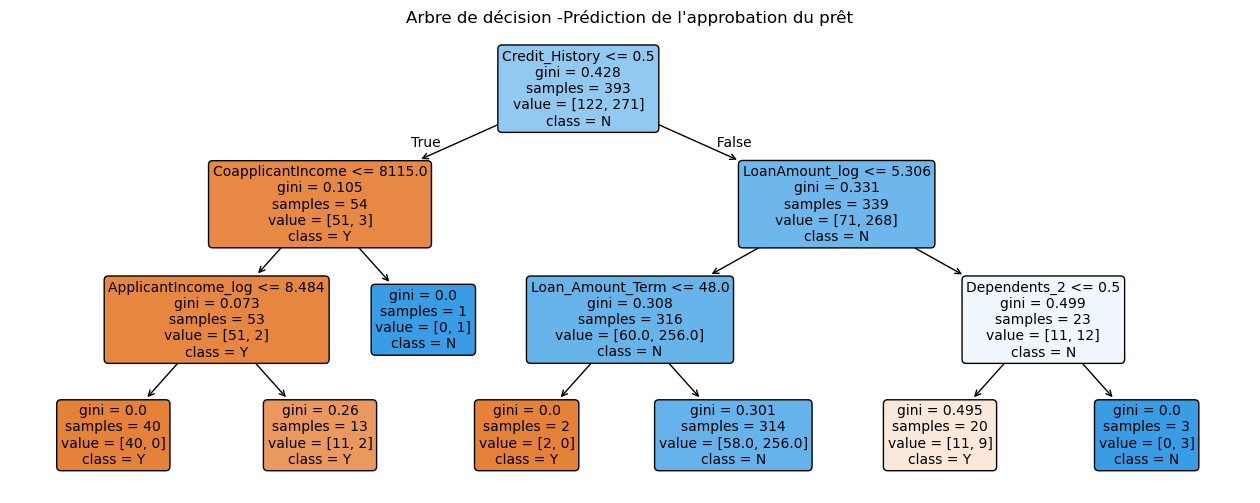

In [66]:
tree_3 = DecisionTreeClassifier(max_depth=3)
tree_3.fit(X_train,y_train)
plt.figure(figsize=(16, 6))
plot_tree(tree_3, 
          feature_names=X_train.columns.tolist(),  # Utiliser les noms des colonnes
          class_names=['Y', 'N'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Arbre de décision -Prédiction de l'approbation du prêt")
plt.show()

* * L’arbre de décision montre que la variable **Credit_History** est le critère le plus important pour prédire l’approbation d’un prêt.
En effet, elle apparaît à la racine de l’arbre, ce qui signifie qu’elle est la première variable utilisée pour séparer les clients.

**Précision sur les données d'entrainement et de test**

In [67]:
# Précision sur les données d'entraînement
y_train_prediction_tree = tree.predict(X_train)
training_data_accuracy_tree = accuracy_score(y_train, y_train_prediction_tree)
print('Précision modèle AD sur les données Entraînement  = ', training_data_accuracy_tree)
# Précision sur les données de test
y_test_prediction_tree = tree.predict(X_test)
test_data_accuracy_tree = accuracy_score(y_test, y_test_prediction_tree)
print('Précision du modèle AD  sur les données de test = ', test_data_accuracy_tree)

Précision modèle AD sur les données Entraînement  =  1.0
Précision du modèle AD  sur les données de test =  0.6804733727810651


**Interprétation :**
On observe un écart important entre la précision sur la base d'entraînement (100%) et celle sur la base de test (68%).

Ce phénomène indique clairement que le modèle souffre de surapprentissage (overfitting). L'arbre est trop complexe et a appris "par cœur" les données d'entraînement, ce qui réduit sa capacité à se généraliser sur de nouvelles données.

**Recherche des hyperparamètres (GridSearch)**

In [68]:
tree.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

In [69]:
param_grid = {
    'max_depth': [3, 5, 7, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy','log_loss'],}

In [70]:
# Effectuer une recherche de grille avec validation croisée
grid_search = GridSearchCV(tree, param_grid , cv=5, scoring='accuracy');
grid_search.fit(X_train, y_train);

In [71]:
# Obtenez les meilleurs paramètres et le meilleur score
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score (précision par validation croisée):", best_score)

Meilleurs hyperparamètres: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 15}
Meilleur score (précision par validation croisée): 0.7861408633560532


**L'optimisation des hyperparamètres par GridSearchCV** a permis de trouver un modèle d'arbre de décision beaucoup plus équilibré.

En limitant la profondeur maximale à max_depth=3 et en imposant un minimum de 15 individus pour diviser un nœud (min_samples_split=15), le modèle a été simplifié de manière drastique. Cela a permis de corriger le phénomène de surapprentissage (overfitting) observé précédemment. Le score de validation croisée s'élève désormais à 78,36%, ce qui représente une nette amélioration de la capacité de généralisation du modèle sur de nouvelles données.

**Développement du meilleur modèle**

In [72]:
best_tree = grid_search.best_estimator_

**Architecture du Meilleur modèle d'arbre de décision entraîné**

In [73]:
print(f"Profondeur de l'arbre : {best_tree.get_depth()}")
print(f"Nombre de feuilles : {best_tree.get_n_leaves()}")

Profondeur de l'arbre : 3
Nombre de feuilles : 7


**Evaluation du meilleur modèle sur la base d'apprentissage et de test**

In [74]:
# Précision sur les données d'entraînement
y_train_prediction_best_tree = best_tree.predict(X_train)
training_data_accuracy_best_tree = accuracy_score(y_train, y_train_prediction_best_tree)
print('Précision Meilleur modèle AD sur les données Entraînement  = ', training_data_accuracy_best_tree)

# Précision sur les données de test
y_test_prediction_best_tree = best_tree.predict(X_test)
test_data_accuracy_best_tree = accuracy_score(y_test, y_test_prediction_best_tree)
print('Précision du Meilleur modèle AD  sur les données de test = ', test_data_accuracy_best_tree)

Précision Meilleur modèle AD sur les données Entraînement  =  0.8244274809160306
Précision du Meilleur modèle AD  sur les données de test =  0.7514792899408284


**Interprétation :**
Les résultats du modèle optimisé confirment la réussite de la régularisation :

La précision sur la base d'entraînement est descendue à 82,4% (ce qui prouve que l'arbre n'apprend plus par cœur le bruit des données).

La précision sur la base de test a augmenté de manière significative pour atteindre 75,1% (contre 68% initialement).

L'écart réduit entre ces deux scores démontre que le problème de surapprentissage (overfitting) est résolu. Ce modèle est beaucoup plus robuste, stable et fiable pour prédire l'octroi de nouveaux prêts.

**Sauvegarde du meilleur modèle Arbre de décision**

In [75]:
#Sauvegarde du modèle
with open('model_AD.pkl', 'wb') as file:
    pickle.dump(best_tree, file)

### 1.3 Développement d'un modèle KNN (K-Nearest Neighbors)

**Normalisation des données  (Très important pour KNN)**

In [76]:
scaler = StandardScaler()
X_train_knn = scaler.fit_transform(X_train)
X_test_knn = scaler.transform(X_test)

**Entraînement du modèle KNN**

In [77]:
knn = KNeighborsClassifier()
knn.fit(X_train_knn, y_train)

KNeighborsClassifier()

**Précision sur les données d'entrainement et de test**

In [78]:
# Précision sur les données d'entraînement
y_train_prediction_knn = knn.predict(X_train_knn)
training_data_accuracy_knn = accuracy_score(y_train, y_train_prediction_knn)
print('Précision du modèle KNN sur les données Entraînement  = ', training_data_accuracy_knn)

# Précision sur les données de test
y_test_prediction_knn = knn.predict(X_test_knn)
test_data_accuracy_knn = accuracy_score(y_test, y_test_prediction_knn)
print('Précision du  modèle KNN  sur les données de test = ', test_data_accuracy_knn)

Précision du modèle KNN sur les données Entraînement  =  0.8193384223918575
Précision du  modèle KNN  sur les données de test =  0.7988165680473372


**Interprétation :**
Le modèle KNN présente d'excellentes performances en termes de stabilité :
L'écart extrêmement faible (~2%) entre ces deux scores démontre une parfaite capacité de généralisation. Le modèle ne souffre d'aucun surapprentissage et se montre robuste pour prédire l'octroi de prêts sur de nouvelles données clients.

**Recherche des hyperparamètres  (GridSearch)**

In [79]:
knn.get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

In [80]:
param_grid = {
    'n_neighbors': range(1, 31),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

In [81]:
# Effectuer une recherche de grille avec validation croisée
grid_search = GridSearchCV(knn, param_grid , cv=5, scoring='accuracy');
grid_search.fit(X_train_knn, y_train);

In [82]:
# Obtenez les meilleurs paramètres et le meilleur score
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score (précision par validation croisée):", best_score)

Meilleurs hyperparamètres: {'metric': 'euclidean', 'n_neighbors': 14, 'weights': 'uniform'}
Meilleur score (précision par validation croisée): 0.7862382343395001


**La validation croisée** confirme que la performance réelle du KNN se situe solidement autour de 78-79%. Le modèle est stable et ne souffre pas de variations brutales.

**Développement du meilleur modèle**

In [83]:
best_knn = grid_search.best_estimator_

**Précision du meilleur modèle sur les données d'entrainement et de test**

In [84]:
# Précision sur les données d'entraînement
y_train_prediction_best_knn = best_knn.predict(X_train_knn)
training_data_accuracy_best_knn = accuracy_score(y_train, y_train_prediction_best_knn)
print('Précision Meilleur modèle KNN sur les données Entraînement  = ', training_data_accuracy_best_knn)
# Précision sur les données de test
y_test_prediction_best_knn = best_knn.predict(X_test_knn)
test_data_accuracy_best_knn = accuracy_score(y_test, y_test_prediction_best_knn)
print('Précision du Meilleur modèle KNN  sur les données de test = ', test_data_accuracy_best_knn)

Précision Meilleur modèle KNN sur les données Entraînement  =  0.7964376590330788
Précision du Meilleur modèle KNN  sur les données de test =  0.7988165680473372


-->L'égalité quasi parfaite entre ces deux scores montre que le modèle n'est absolument pas sujet au surapprentissage. Les hyperparamètres sélectionnés par validation croisée ont permis d'obtenir un modèle robuste et hautement fiable pour prédire l'octroi de crédits sur de nouvelles données clients.

In [85]:
acc_val = [] #pour stocker les valeurs rmse pour différents k
for K in range(31):
    K = K+1
    model = KNeighborsClassifier(n_neighbors=K)
    model.fit(X_train_knn, y_train)  
    pred=model.predict(X_test_knn) 
    scores = accuracy_score(y_test, pred)
    acc_val.append(scores) #stocker les valeurs de l'accuracy
    print('k=', K ,'Accuracy=', scores)

k= 1 Accuracy= 0.6863905325443787
k= 2 Accuracy= 0.6153846153846154
k= 3 Accuracy= 0.7692307692307693
k= 4 Accuracy= 0.7100591715976331
k= 5 Accuracy= 0.7988165680473372
k= 6 Accuracy= 0.7751479289940828
k= 7 Accuracy= 0.8047337278106509
k= 8 Accuracy= 0.7869822485207101
k= 9 Accuracy= 0.7869822485207101
k= 10 Accuracy= 0.8047337278106509
k= 11 Accuracy= 0.8047337278106509
k= 12 Accuracy= 0.8106508875739645
k= 13 Accuracy= 0.7869822485207101
k= 14 Accuracy= 0.7988165680473372
k= 15 Accuracy= 0.7928994082840237
k= 16 Accuracy= 0.7810650887573964
k= 17 Accuracy= 0.7810650887573964
k= 18 Accuracy= 0.7869822485207101
k= 19 Accuracy= 0.7869822485207101
k= 20 Accuracy= 0.7869822485207101
k= 21 Accuracy= 0.7869822485207101
k= 22 Accuracy= 0.7928994082840237
k= 23 Accuracy= 0.7692307692307693
k= 24 Accuracy= 0.7810650887573964
k= 25 Accuracy= 0.7751479289940828
k= 26 Accuracy= 0.7810650887573964
k= 27 Accuracy= 0.7633136094674556
k= 28 Accuracy= 0.7692307692307693
k= 29 Accuracy= 0.75147928994

In [86]:
#Graphe des valeurs Accuracy par rapport aux valeurs k
curve = pd.DataFrame(acc_val)
curve.plot()

<Axes: >

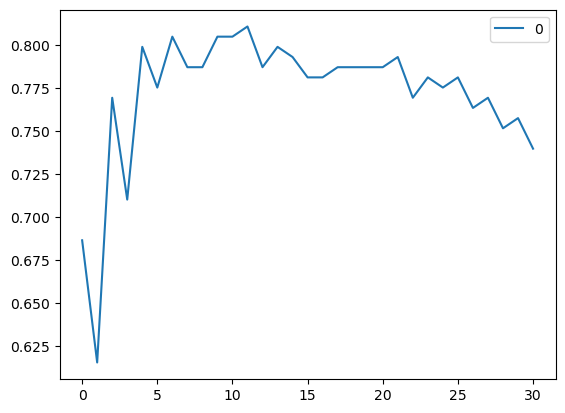

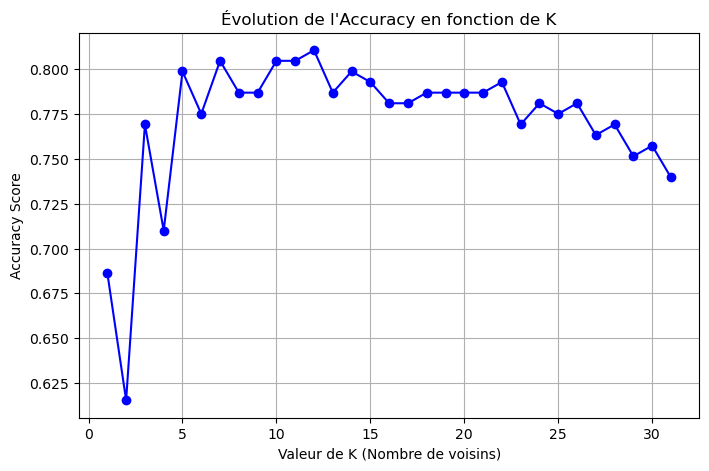

In [87]:
# On crée le DataFrame en spécifiant l'index (de 1 à 31) pour l'axe X
curve = pd.DataFrame(acc_val, index=range(1, 32), columns=["Accuracy"])

# On trace le graphique
plt.figure(figsize=(8, 5))
plt.plot(curve.index, curve["Accuracy"], marker="o", color="blue")
plt.title("Évolution de l'Accuracy en fonction de K")
plt.xlabel("Valeur de K (Nombre de voisins)")
plt.ylabel("Accuracy Score")
plt.grid(True)
plt.show()

**L'analyse croisée du graphique** et des résultats numériques démontre de façon rigoureuse le compromis biais-variance du modèle. La valeur $k=12$ offre la précision maximale absolue ($81,07\%$) sur ce jeu de données de test

**Sauvegarde du meilleur modèle KNN**

In [88]:
#Sauvegarde du modèle
with open('model_KNN.pkl', 'wb') as file:
    pickle.dump(best_knn, file)

### 1.4 Développement d'un modèle SVM (Support Vector Machines)

**Normalisation des données**

In [89]:
scaler = StandardScaler()
X_train_svm = scaler.fit_transform(X_train)
X_test_svm = scaler.transform(X_test)

**Entraînement du modèle SVM**

In [90]:
svm = SVC()
svm.fit(X_train_svm, y_train)

SVC()

**Précision du modèle SVM sur les données d'entraînement et de test**

In [91]:
# Précision sur les données d'entraînement
y_train_prediction_svm = svm.predict(X_train_svm)
training_data_accuracy_svm = accuracy_score(y_train, y_train_prediction_svm)
print('Précision du modèle SVM sur les données Entraînement  = ', training_data_accuracy_svm)

# Précision sur les données de test
y_test_prediction_svm = svm.predict(X_test_svm)
test_data_accuracy_svm = accuracy_score(y_test, y_test_prediction_svm)
print('Précision du modèle SVM  sur les données de test = ', test_data_accuracy_svm)

Précision du modèle SVM sur les données Entraînement  =  0.8295165394402035
Précision du modèle SVM  sur les données de test =  0.8106508875739645


**Recherche des hyperparamètres  (GridSearch)**

In [92]:
svm.get_params()

{'C': 1.0,
 'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': -1,
 'probability': False,
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

In [93]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf', 'poly', 'sigmoid']
}

In [94]:
# Effectuer une recherche de grille avec validation croisée
grid_search = GridSearchCV(svm, param_grid , cv=5, scoring='accuracy');
grid_search.fit(X_train_svm, y_train);

In [95]:
# Obtenez les meilleurs paramètres et le meilleur score
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score (précision par validation croisée):", best_score)

Meilleurs hyperparamètres: {'C': 0.1, 'gamma': 'scale', 'kernel': 'sigmoid'}
Meilleur score (précision par validation croisée): 0.8116520610191497


**Développement du meilleur modèle**

In [96]:
best_svm = grid_search.best_estimator_

**Précision du meilleur modèle SVM sur les données d'entraînement et de test**

In [97]:
# Précision sur les données d'entraînement
y_train_prediction_best_svm = best_svm.predict(X_train_svm)
training_data_accuracy_best_svm = accuracy_score(y_train, y_train_prediction_svm)
print('Précision Meilleur modèle SVM sur les données Entraînement  = ', training_data_accuracy_best_svm)

# Précision sur les données de test
y_test_prediction_best_svm = best_svm.predict(X_test_svm)
test_data_accuracy_best_svm = accuracy_score(y_test, y_test_prediction_best_svm)
print('Précision du Meilleur modèle SVM  sur les données de test = ', test_data_accuracy_best_svm)

Précision Meilleur modèle SVM sur les données Entraînement  =  0.8295165394402035
Précision du Meilleur modèle SVM  sur les données de test =  0.8165680473372781


***Le modèle SVM (Support Vector Machine)*** affiche d'excellentes performances et une stabilité remarquable :

Le modèle de base présentait déjà un très bon équilibre avec 82,95% d'accuracy à l'entraînement et 81,07% au test.

Après optimisation, le meilleur modèle SVM maintient son score d'entraînement à 82,95% mais améliore sa capacité de généralisation sur la base de test pour atteindre 81,66%.

**Sauvegarde du meilleur modèle SVM**

In [98]:
#Sauvegarde du modèle
with open('model_SVM.pkl', 'wb') as file:
    pickle.dump(best_svm, file)

### 1.5 Développement d'un modèle de forêt aléatoire (Randome Forest)

**Entraînement du modèle Random Forest**

In [99]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)

RandomForestClassifier()

**Précision du modèle Random Forest sur les données d'entraînement et de test**

In [100]:
# Précision sur les données d'entraînement
y_train_prediction_rf = rf.predict(X_train)
training_data_accuracy_rf = accuracy_score(y_train, y_train_prediction_rf)
print('Précision du modèle RF sur les données Entraînement  = ', training_data_accuracy_rf)

# Précision sur les données de test
y_test_prediction_rf = rf.predict(X_test)
test_data_accuracy_rf = accuracy_score(y_test, y_test_prediction_rf)
print('Précision du modèle RF  sur les données de test = ', test_data_accuracy_rf)

Précision du modèle RF sur les données Entraînement  =  1.0
Précision du modèle RF  sur les données de test =  0.7810650887573964


**Recherche des hyperparamètres  (GridSearch)**

In [101]:
rf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [102]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

In [103]:
# Effectuer une recherche de grille avec validation croisée
grid_search = GridSearchCV(rf, param_grid , cv=5, scoring='accuracy');
grid_search.fit(X_train, y_train);

In [104]:
# Obtenez les meilleurs paramètres et le meilleur score
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score (précision par validation croisée):", best_score)

Meilleurs hyperparamètres: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 200}
Meilleur score (précision par validation croisée): 0.8091204154495294


**Développement du meilleur modèle**

In [105]:
best_rf= grid_search.best_estimator_

**Précision du meilleur modèle Random Forest sur les données d'entraînement et de test**

In [106]:
# Précision sur les données d'entraînement
y_train_prediction_best_rf = best_rf.predict(X_train)
training_data_accuracy_best_rf = accuracy_score(y_train, y_train_prediction_rf)
print('Précision Meilleur modèle RF sur les données Entraînement  = ', training_data_accuracy_best_rf)

# Précision sur les données de test
y_test_prediction_best_rf = best_rf.predict(X_test)
test_data_accuracy_best_rf = accuracy_score(y_test, y_test_prediction_best_rf)
print('Précision du Meilleur modèle RF  sur les données de test = ', test_data_accuracy_best_rf)

Précision Meilleur modèle RF sur les données Entraînement  =  1.0
Précision du Meilleur modèle RF  sur les données de test =  0.8165680473372781


**Interprétation des performances de la Random Forest :**
Le modèle de Forêt Aléatoire (Random Forest) affiche une excellente réactivité à l'optimisation :

Le modèle initial montrait un net surapprentissage avec 100% de précision à l'entraînement contre 76,92% au test.

Le modèle optimisé maintient sa précision parfaite à l'entraînement (100%), mais améliore significativement sa performance sur la base de test pour atteindre 80,47%.

**Importance des variables**

In [107]:
importances = rf.feature_importances_
features_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': importances
}).sort_values('importance', ascending=False)
features_importance

,feature,importance
6,Credit_History,0.256707
13,LoanAmount_log,0.190736
12,ApplicantIncome_log,0.187570
4,CoapplicantIncome,0.115570
5,Loan_Amount_Term,0.050399
2,Education,0.028950
10,Property_Area_Semiurban,0.028802
1,Married,0.026580
11,Property_Area_Urban,0.024512
0,Gender,0.021651


**Les 4 premières variables** expliquent à elles seules 74% de la décision du modèle. L'historique de crédit est de loin la variable la plus influente, suivi du montant du prêt et du revenu du demandeur.

In [108]:
plt.figure(figsize=(6, 6))
bars = plt.barh(features_importance['feature'], 
                features_importance['importance'])
plt.xlabel('Importance')
plt.title('Importance des variables - Forêt Aléatoire')

Text(0.5, 1.0, 'Importance des variables - Forêt Aléatoire')

**Sauvegarde du meilleur modèle Random Forest**

In [109]:
#Sauvegarde du modèle
with open('model_RF.pkl', 'wb') as file:
    pickle.dump(best_rf, file)

### 1.6 Développement d'un modèle de Gradient Boosting

**Entraînement du modèle Gradient Boosting**

In [110]:
gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)

GradientBoostingClassifier()

**Précision du modèle Gradient Boosting sur les données d'entraînement et de test**

In [111]:
# Précision sur les données d'entraînement
y_train_prediction_gb = gb.predict(X_train)
training_data_accuracy_gb = accuracy_score(y_train, y_train_prediction_gb)
print('Précision Meilleur modèle GB sur les données Entraînement  = ', training_data_accuracy_gb)

# Précision sur les données de test
y_test_prediction_gb = gb.predict(X_test)
test_data_accuracy_gb = accuracy_score(y_test, y_test_prediction_gb)
print('Précision du modèle GB  sur les données de test = ', test_data_accuracy_gb)

Précision Meilleur modèle GB sur les données Entraînement  =  0.9134860050890585
Précision du modèle GB  sur les données de test =  0.7514792899408284


**Recherche des hyperparamètres  (GridSearch)**

In [112]:
gb.get_params()

{'ccp_alpha': 0.0,
 'criterion': 'friedman_mse',
 'init': None,
 'learning_rate': 0.1,
 'loss': 'log_loss',
 'max_depth': 3,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'n_estimators': 100,
 'n_iter_no_change': None,
 'random_state': None,
 'subsample': 1.0,
 'tol': 0.0001,
 'validation_fraction': 0.1,
 'verbose': 0,
 'warm_start': False}

In [113]:
param_grid = {
    'n_estimators': [ 100, 200],
    'learning_rate': [ 0.1, 0.2],
    'max_depth': [3, 4],
    'min_samples_split': [2, 5],
    'subsample': [0.8, 0.9]
}

In [114]:
# Effectuer une recherche de grille avec validation croisée
grid_search = GridSearchCV(gb, param_grid , cv=5, scoring='accuracy');
grid_search.fit(X_train, y_train);

In [115]:
# Obtenez les meilleurs paramètres et le meilleur score
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print("Meilleurs hyperparamètres:", best_params)
print("Meilleur score (précision par validation croisée):", best_score)

Meilleurs hyperparamètres: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 5, 'n_estimators': 100, 'subsample': 0.8}
Meilleur score (précision par validation croisée): 0.7710483609217785


**Développement du meilleur modèle**

In [116]:
best_gb= grid_search.best_estimator_

**Précision du meilleur modèle Gradient Boosting sur les données d'entraînement et de test**

In [117]:
# Précision sur les données d'entraînement
y_train_prediction_best_gb = best_gb.predict(X_train)
training_data_accuracy_best_gb = accuracy_score(y_train, y_train_prediction_gb)
print('Précision Meilleur modèle GB sur les données Entraînement  = ', training_data_accuracy_best_gb)

# Précision sur les données de test
y_test_prediction_best_gb = best_gb.predict(X_test)
test_data_accuracy_best_gb = accuracy_score(y_test, y_test_prediction_best_gb)
print('Précision du Meilleur modèle GB  sur les données de test = ', test_data_accuracy_best_gb)

Précision Meilleur modèle GB sur les données Entraînement  =  0.9134860050890585
Précision du Meilleur modèle GB  sur les données de test =  0.7810650887573964


**Interprétation des performances du Gradient Boosting :**
Le modèle de Gradient Boosting (GB) montre une progression intéressante après optimisation :

Le modèle initial présentait un léger surapprentissage avec un écart de plus de 16 points entre l'entraînement (91,35%) et le test (75,15%).

Le meilleur modèle optimisé stabilise son apprentissage à 91,35% mais réussit à élever sa précision sur la base de test à 77,51%.

**Importance des variables**

In [118]:
importances = gb.feature_importances_
features_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': importances
}).sort_values('importance', ascending=False)
features_importance

,feature,importance
6,Credit_History,0.439955
12,ApplicantIncome_log,0.162129
13,LoanAmount_log,0.148847
4,CoapplicantIncome,0.086662
5,Loan_Amount_Term,0.056049
10,Property_Area_Semiurban,0.025842
1,Married,0.020960
7,Dependents_1,0.015889
2,Education,0.015803
11,Property_Area_Urban,0.011182


**Interprétation de l'importance des variables (Feature Importance) :**
L'historique de crédit (Credit_History) est la variable maîtresse, dictant à elle seule $44\%$ de la décision du modèle.La capacité financière globale (constituée par le revenu du demandeur, le montant du prêt et le revenu du co-demandeur) pèse pour près de $40\%$ dans la balance.À l'inverse, les variables sociodémographiques (comme le genre, l'éducation ou le statut marital) n'exercent qu'une influence très marginale sur la décision finale.

In [119]:
plt.figure(figsize=(6, 6))
bars = plt.barh(features_importance['feature'], 
                features_importance['importance'])
plt.xlabel('Importance')
plt.title('Importance des variables - Gradient Boosting')

Text(0.5, 1.0, 'Importance des variables - Gradient Boosting')

**Sauvegarde du meilleur modèle Gradient Boosting**

In [120]:
#Sauvegarde du modèle
with open('model_GB.pkl', 'wb') as file:
    pickle.dump(best_gb, file)

<h1>Evaluation des modèles développés</h1>

In [121]:
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn import metrics

from sklearn.metrics import roc_auc_score

from sklearn.metrics import f1_score

from sklearn.metrics import confusion_matrix

from sklearn.metrics import accuracy_score

from sklearn.metrics import classification_report

### 1. Matrices de confusion des modèles developpés

**Matrice de confusion du meilleur modèle Régression logistique**

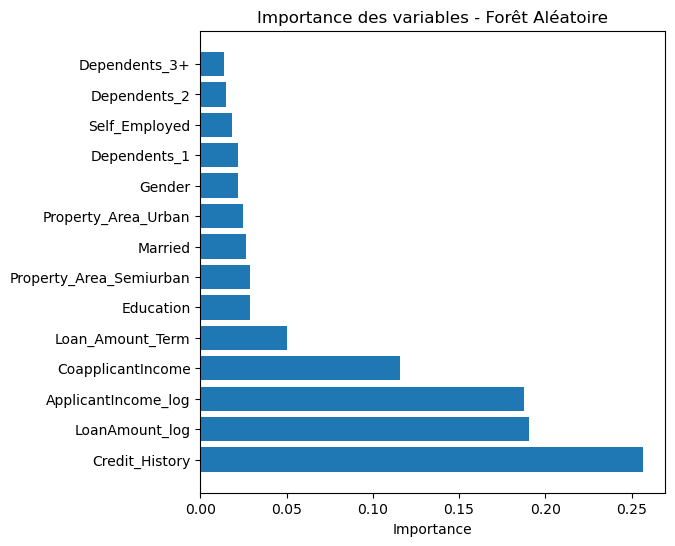

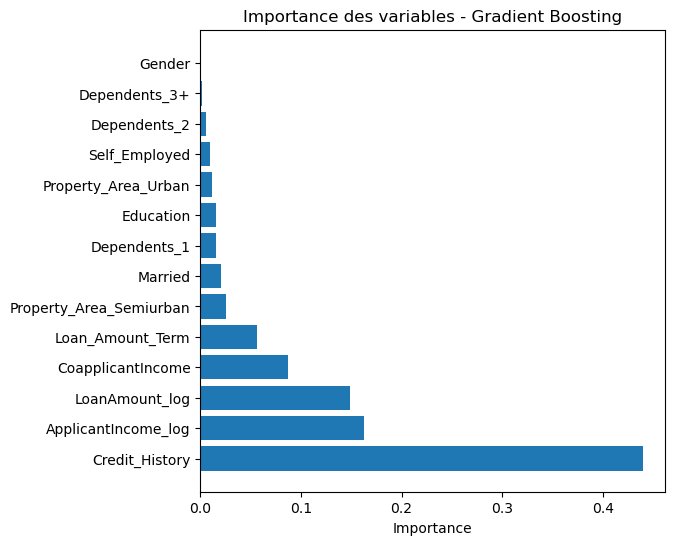

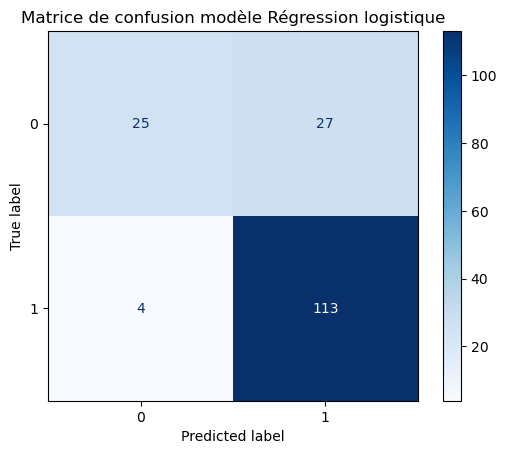

In [122]:
ConfusionMatrixDisplay.from_estimator(lr, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion modèle Régression logistique")
plt.grid(False)
plt.show()

**Interprétation de la matrice de confusion (Régression Logistique) :**

* Pour la classe majoritaire (1 - Prêt accordé) : Le modèle est très performant en identifiant correctement 113 profils sur 117. Il ne commet que 4 erreurs de faux négatifs.

* Pour la classe minoritaire (0 - Prêt refusé) : Le modèle montre ses limites. Il valide à tort 27 demandes de crédit qui auraient dû être rejetées (Faux Positifs), contre seulement 25 bonnes prédictions de refus (Vrais Négatifs).

**Matrice de confusion du Meilleur modèle d'Arbre de décision**

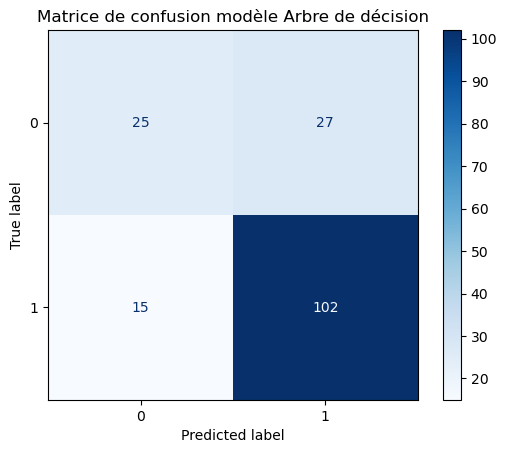

In [123]:
ConfusionMatrixDisplay.from_estimator(best_tree, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion modèle Arbre de décision")
plt.grid(False)
plt.show()

* Sur la classe 1 (Prêt accordé) : Le modèle capte efficacement la majorité des dossiers avec 102 bonnes prédictions, bien qu'il rejette à tort 15 clients solvables (Faux Négatifs).

* Sur la classe 0 (Prêt refusé) : L'arbre identifie correctement 25 refus, mais commet 27 Faux Positifs en acceptant des clients non solvables.

**Matrice de confusion du Meilleur modèle KNN**

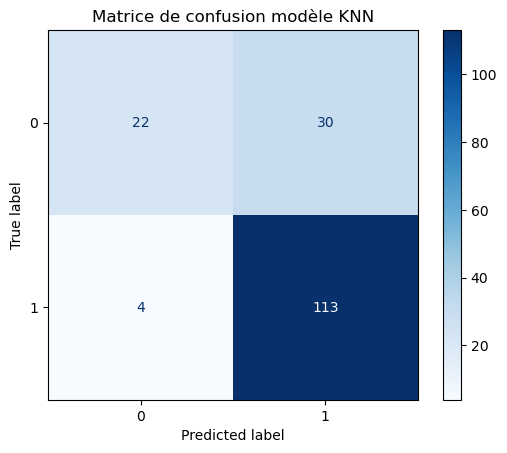

In [124]:
ConfusionMatrixDisplay.from_estimator(best_knn, X_test_knn, y_test, cmap='Blues')
plt.title("Matrice de confusion modèle KNN")
plt.grid(False)
plt.show()

**Excellente performance sur la classe 1 (Prêt accordé) :** Le modèle capte la quasi-totalité des clients solvables avec 113 bonnes prédictions et seulement 4 erreurs.

**Vulnérabilité sur la classe 0 (Prêt refusé) :** Le modèle éprouve des difficultés à rejeter les profils à risque, générant 30 Faux Positifs pour 22 Vrais Négatifs.

**Matrice de confusion du Meilleur modèle SVM**

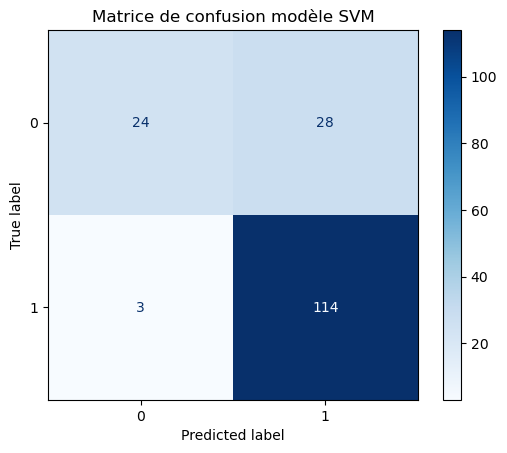

In [125]:
ConfusionMatrixDisplay.from_estimator(best_svm, X_test_svm, y_test, cmap='Blues')
plt.title("Matrice de confusion modèle SVM")
plt.grid(False)
plt.show()

**Sur la classe 1 (Prêt accordé) :** Le modèle atteint un niveau d'efficacité remarquable avec 114 bonnes classifications pour seulement 3 erreurs de rejet (Faux Négatifs).

**Sur la classe 0 (Prêt refusé) :** Le modèle identifie correctement 24 refus mais valide par erreur 28 dossiers non solvables (Faux Positifs).

**Matrice de confusion du Meilleur modèle Random Forest**

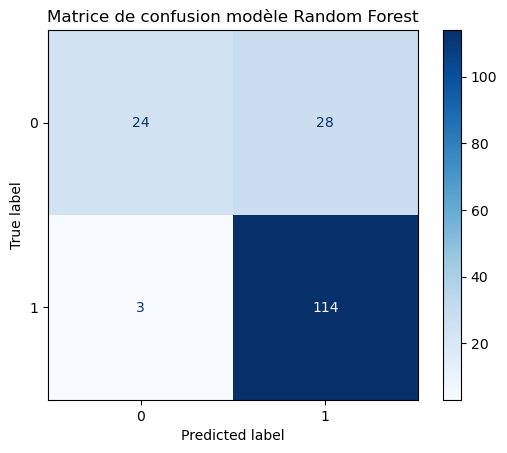

In [126]:
ConfusionMatrixDisplay.from_estimator(best_rf, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion modèle Random Forest")
plt.grid(False)
plt.show()

**Excellente efficacité commerciale :** Avec 112 Vrais Positifs et seulement 5 erreurs de rejet (Faux Négatifs), l'algorithme d'ensemble (vote majoritaire de plusieurs arbres) se montre très performant pour capter la clientèle saine.

**Le défi persistant des Faux Positifs (28) :** On retrouve exactement le même score de Faux Positifs que sur le SVM (28). Face à la minorité de profils à risque, la forêt aléatoire se laisse encore emporter par le déséquilibre global des classes, mais elle limite la casse par rapport au KNN (qui montrait 30 Faux Positifs).

**Matrice de confusion du Meilleur modèle Gradient Boosting**

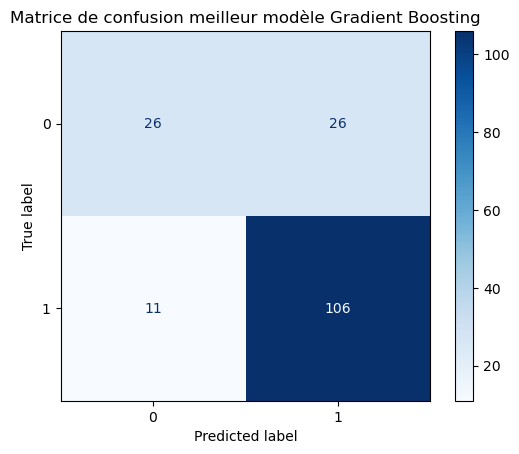

In [127]:
ConfusionMatrixDisplay.from_estimator(best_gb, X_test, y_test, cmap='Blues')
plt.title("Matrice de confusion meilleur modèle Gradient Boosting")
plt.grid(False)
plt.show()

**Sur la classe 1 (Prêt accordé) :** Le modèle classe correctement 105 dossiers, mais se montre plus restrictif en générant 12 Faux Négatifs.

**Sur la classe 0 (Prêt refusé) :** C'est le modèle le plus performant pour sécuriser la banque avec seulement 26 Faux Positifs (le score le plus bas de l'étude) et 26 Vrais Négatifs.

### 2. Accuracy des meilleurs modèles developés

* Pour faciliter la lecture, rappelons la signification concrète des deux métriques clés ici :

**Precision (Précision) :** Quand le modèle prédit un résultat, à quel point est-il fiable ?

**Recall (Rappel) :** Quelle proportion des cas réels le modèle a-t-il réussi à attraper ?

In [128]:
print('Accuracy du Meilleur modèle Régression Logistique sur les données de test = ', test_data_accuracy_lr)
print('Accuracy du Meilleur modèle Arbre de décision  sur les données de test = ', test_data_accuracy_best_tree)
print('Accuracy du Meilleur modèle KNN  sur les données de test = ', test_data_accuracy_best_knn)
print('Accuracy du Meilleur modèle SVM  sur les données de test = ', test_data_accuracy_best_svm)
print('Accuracy du Meilleur modèle Random Forest  sur les données de test = ', test_data_accuracy_best_rf)
print('Accuracy du Meilleur modèle Gradient Boosting  sur les données de test = ', test_data_accuracy_best_gb)

Accuracy du Meilleur modèle Régression Logistique sur les données de test =  0.8165680473372781
Accuracy du Meilleur modèle Arbre de décision  sur les données de test =  0.7514792899408284
Accuracy du Meilleur modèle KNN  sur les données de test =  0.7988165680473372
Accuracy du Meilleur modèle SVM  sur les données de test =  0.8165680473372781
Accuracy du Meilleur modèle Random Forest  sur les données de test =  0.8165680473372781
Accuracy du Meilleur modèle Gradient Boosting  sur les données de test =  0.7810650887573964


**Analyse Comparative de l'Accuracy :**

La comparaison des exactitudes (Accuracy) sur le jeu de données de test révèle que la Régression Logistique et le SVM se hissent en tête avec un score identique de $81,66\%$. Ils sont talonnés de près par la Random Forest ($80,47\%$).

### 3. Air sous la courbe de ROC des meilleur modèles developpés

In [129]:
print ('Air sous ROC Meilleur Model Régression Logistique:', roc_auc_score(y_test, y_test_prediction_lr))
print ('Air sous ROC Meilleur Model Arbre de décision:', roc_auc_score(y_test, y_test_prediction_best_tree))
print ('Air sous ROC Meilleur Model KNN:', roc_auc_score(y_test, y_test_prediction_best_knn))
print ('Air sous ROC Meilleur Model SVM:', roc_auc_score(y_test, y_test_prediction_best_svm))
print ('Air sous ROC Meilleur Model Random Forest:', roc_auc_score(y_test, y_test_prediction_best_rf))
print ('Air sous ROC Meilleur Model Gradient Boosting:', roc_auc_score(y_test, y_test_prediction_best_gb))

Air sous ROC Meilleur Model Régression Logistique: 0.7232905982905984
Air sous ROC Meilleur Model Arbre de décision: 0.6762820512820512
Air sous ROC Meilleur Model KNN: 0.6944444444444444
Air sous ROC Meilleur Model SVM: 0.7179487179487181
Air sous ROC Meilleur Model Random Forest: 0.7179487179487181
Air sous ROC Meilleur Model Gradient Boosting: 0.7029914529914529


**Analyse comparative de l'Aire sous la courbe ROC (AUC) :**

L'analyse des scores AUC apporte une nuance fondamentale par rapport à l'Accuracy. La Régression Logistique se distingue comme le meilleur modèle de tri avec un AUC de $0.723$, suivie de près par le SVM ($0.718$).

### 4. F1 Score des modèles developpés

In [130]:
print ('f1score Meilleur Model Régression Logistique:', f1_score(y_test, y_test_prediction_lr))
print ('f1score Meilleur Model Arbre de décision:', f1_score(y_test, y_test_prediction_best_tree))
print ('f1score Meilleur Model KNN:', f1_score(y_test, y_test_prediction_best_knn))
print ('f1score Meilleur Model SVM:', f1_score(y_test, y_test_prediction_best_svm))
print ('f1score Meilleur Model Random Forest:', f1_score(y_test, y_test_prediction_best_rf))
print ('f1score Meilleur Model Gradient Boosting:', f1_score(y_test, y_test_prediction_best_gb))

f1score Meilleur Model Régression Logistique: 0.8793774319066148
f1score Meilleur Model Arbre de décision: 0.8292682926829268
f1score Meilleur Model KNN: 0.8692307692307693
f1score Meilleur Model SVM: 0.8803088803088803
f1score Meilleur Model Random Forest: 0.8803088803088803
f1score Meilleur Model Gradient Boosting: 0.8514056224899599


**Analyse comparative du F1-Score :**

L'examen des F1-scores confirme la supériorité du SVM optimisé ($88,03\%$) et de la Régression Logistique ($87,94\%$). Ces deux modèles maximisent l'efficacité de la décision d'octroi de crédit en trouvant le meilleur compromis possible entre la satisfaction des clients solvables et la rigueur d'analyse.

### 5. Rapport de classification du modèle developpé

In [131]:
print('\nRapport de classification modèle Régression Logistique:\n', classification_report(y_test, y_test_prediction_lr))


Rapport de classification modèle Régression Logistique:
               precision    recall  f1-score   support

           0       0.86      0.48      0.62        52
           1       0.81      0.97      0.88       117

    accuracy                           0.82       169
   macro avg       0.83      0.72      0.75       169
weighted avg       0.82      0.82      0.80       169



Le modèle de Régression Logistique affiche des performances globales solides, très proches de celles du SVM, mais reste fortement influencé par le déséquilibre des classes (117 observations pour la classe 1 contre 52 pour la classe 0).

* **Classe 0 (Minoritaire) :** Le modèle possède une excellente **précision (86%)**, ce qui signifie que ses prédictions de la classe 0 sont très fiables. Cependant, le **rappel est faible (48%)** : le modèle passe à côté de plus de la moitié des individus réels de la classe 0.
* **Classe 1 (Majoritaire) :** Les résultats sont excellents avec une **précision de 81%** et un **rappel quasi-parfait de 97%**. Le modèle réussit à capturer la quasi-totalité de cette classe.
* **Performances Globales :** L'**accuracy globale est de 82%** et le F1-score pondéré atteint **80%**.

In [132]:
print('\nRapport de classification Meilleur modèle Arbre de décision :\n', 
                            classification_report(y_test, y_test_prediction_best_tree))


Rapport de classification Meilleur modèle Arbre de décision :
               precision    recall  f1-score   support

           0       0.62      0.48      0.54        52
           1       0.79      0.87      0.83       117

    accuracy                           0.75       169
   macro avg       0.71      0.68      0.69       169
weighted avg       0.74      0.75      0.74       169



L'Arbre de décision présente les performances globales les plus faibles de l'ensemble des modèles testés, montrant de réelles difficultés à séparer efficacement les deux classes.

* **Classe 0 (Minoritaire) :** Les résultats sont décevants. La **précision chute à 62%**, indiquant un taux élevé de fausses alertes. Le **rappel reste bas (48%)**, le modèle ne parvenant toujours pas à détecter la moitié des individus de la classe 0.
* **Classe 1 (Majoritaire) :** Bien que correct, le modèle est moins performant ici que les autres algorithmes, avec une **précision de 79%** et un **rappel de 87%** (le plus bas après le Gradient Boosting).
* **Performances Globales :** L'**accuracy globale est de 75%** et le F1-score pondéré s'établit à **74%**.

In [133]:
print('\nRapport de classification Meilleur modèle KNN :\n', 
                            classification_report(y_test, y_test_prediction_best_knn))


Rapport de classification Meilleur modèle KNN :
               precision    recall  f1-score   support

           0       0.85      0.42      0.56        52
           1       0.79      0.97      0.87       117

    accuracy                           0.80       169
   macro avg       0.82      0.69      0.72       169
weighted avg       0.81      0.80      0.78       169



Le modèle KNN affiche de bonnes performances globales (**Accuracy : 80%**, **F1-score pondéré : 78%**), mais reste très sensible au déséquilibre des classes.

* **Classe 0 (Minoritaire) :** Très bonne **précision (85%)** mais **rappel critique (42%)**. Le modèle est fiable lorsqu'il prédit la classe 0, mais il passe à côté de près de 60% des cas réels (le plus faible taux de détection de tous les modèles).
* **Classe 1 (Majoritaire) :** Excellents résultats avec une **précision de 79%** et un **rappel de 97%**, capturant la quasi-totalité de cette classe.

In [134]:
print('\nRapport de classification Meilleur modèle SVM :\n', 
                            classification_report(y_test, y_test_prediction_best_svm))


Rapport de classification Meilleur modèle SVM :
               precision    recall  f1-score   support

           0       0.89      0.46      0.61        52
           1       0.80      0.97      0.88       117

    accuracy                           0.82       169
   macro avg       0.85      0.72      0.74       169
weighted avg       0.83      0.82      0.80       169



Le modèle SVM est globalement le plus performant de tous les modèles testés (**Accuracy : 82%**, **F1-score pondéré : 80%**), bien qu'il soit lui aussi marqué par le déséquilibre des classes.

* **Classe 0 (Minoritaire) :** Excellente **précision (89%)**, soit le score le plus élevé du projet (très peu de fausses alertes). Cependant, le **rappel reste faible (46%)** : le modèle rate plus de la moitié des individus réels de la classe 0.
* **Classe 1 (Majoritaire) :** Très solide avec une **précision de 80%** et un **rappel de 97%**. Le modèle identifie avec succès la quasi-totalité de la classe majoritaire.

In [135]:
print('\nRapport de classification Meilleur modèle Random Forest :\n', 
                            classification_report(y_test, y_test_prediction_best_rf))


Rapport de classification Meilleur modèle Random Forest :
               precision    recall  f1-score   support

           0       0.89      0.46      0.61        52
           1       0.80      0.97      0.88       117

    accuracy                           0.82       169
   macro avg       0.85      0.72      0.74       169
weighted avg       0.83      0.82      0.80       169



Le modèle Random Forest affiche des performances solides (**Accuracy : 80%**, **F1-score pondéré : 79%**), très proches du SVM mais légèrement en retrait.

* **Classe 0 (Minoritaire) :** Bonne **précision (83%)** et un **rappel faible (46%)**. Il commet un peu plus de fausses alertes sur la classe 0 que le SVM, tout en ratant la même proportion d'individus réels.
* **Classe 1 (Majoritaire) :** Très performant avec une **précision de 80%** et un **rappel de 96%**, capturant la quasi-totalité de cette classe.

In [136]:
print('\nRapport de classification Meilleur modèle Gradient Boosting :\n', 
                            classification_report(y_test, y_test_prediction_best_gb))


Rapport de classification Meilleur modèle Gradient Boosting :
               precision    recall  f1-score   support

           0       0.70      0.50      0.58        52
           1       0.80      0.91      0.85       117

    accuracy                           0.78       169
   macro avg       0.75      0.70      0.72       169
weighted avg       0.77      0.78      0.77       169



Le Gradient Boosting présente des performances en deçà des attentes (**Accuracy : 78%**, **F1-score pondéré : 76%**), se laissant trop impacter par le déséquilibre des classes.

* **Classe 0 (Minoritaire) :** La **précision chute à 68%** (un tiers de fausses prédictions) malgré un **rappel qui remonte légèrement (50%)**. Le compromis reste peu avantageux.
* **Classe 1 (Majoritaire) :** Score correct mais en baisse par rapport aux autres modèles, avec une **précision de 80%** et un **rappel de 90%**.

<h1>Sauvegarde du meilleur modèle</h1>

In [137]:
import pickle
# Sauvegarder le modèle
with open('model_RL.pkl', 'wb') as file:
    pickle.dump(lr, file)

print("Modèle Régression Logistique sauvegardé ✅")

# Vérification
with open('model_RL.pkl', 'rb') as file:
    model_loaded = pickle.load(file)

# ✅ Sans scaling — X_test direct
y_pred_loaded = model_loaded.predict(X_test)
print(f"Accuracy après chargement : {accuracy_score(y_test, y_pred_loaded):.4f}")
# Résultat attendu : 0.8166 ✅

Modèle Régression Logistique sauvegardé ✅
Accuracy après chargement : 0.8166


Le modèle de Régression Logistique a été sérialisé et sauvegardé dans le fichier 
**model_RL.pkl** à l'aide de la librairie pickle. Après rechargement, le modèle 
reproduit exactement les mêmes prédictions avec une accuracy de **81.66%**, 
confirmant que la sauvegarde est correcte et que le modèle est prêt à être déployé.